In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from simulation_functions import *
from estimator_functions import *
from control_functions import *

In [3]:
def plot_trajectories_time_colored(traj_full, global_time=False, cmap='viridis'):
    fig, ax = plt.subplots(figsize=(5,5))

    if global_time:
        # Concatenate all segments to compute a global colormap
        all_points = np.concatenate(traj_full)
        n_points_total = all_points.shape[0]
        color_positions = np.linspace(0, 1, n_points_total)
        idx = 0  # running index across all segments

    for seg in traj_full:
        n_points = seg.shape[0]
        if global_time:
            colors = cm.get_cmap(cmap)(color_positions[idx:idx+n_points])
            idx += n_points
        else:
            colors = cm.get_cmap(cmap)(np.linspace(0, 1, n_points))

        for i in range(n_points - 1):
            ax.plot(seg[i:i+2, 0], seg[i:i+2, 1], color=colors[i], lw=2)

    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_xlabel("x_0")
    ax.set_ylabel("x_1")
    ax.set_title("Trajectory segments colored by time")
    
    # Add colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Normalized time")
    
    plt.show()

In [4]:
theta = np.pi / 3
A = np.array([
    [0.5, 1/np.tan(theta)],
    [0.0, -0.5]
])

x0 = np.array([0.7, -0.7])
x_prev = x0.copy()

def drift_func(t, x):
    return A @ x

tracker = LinearDynamicsTracker(dim=2, eta_mean=0.01, eta_M=0.01, eta_w=0.01, store_history=True)

def control_func(t, x, dt):
    global x_prev
    b_new = tracker.step(x_prev, x)
    x_prev[:] = x
    return np.zeros_like(x)

def on_restart_cb(k, x_new):
    # reset Mfp/Mpf/Wpp, but keep tracked b and means; clear histories for a clean plot per segment
    #tracker.reset(reset_b=False, reset_means=False, reset_weights=False, reset_history=False)
    0

def on_restart_cb(restarts, x_new):
    # do NOT call tracker.reset() here
    # just reset the trajectory state safely
    print(f"Restart #{restarts}, new x = {x_new}")

np.random.seed(1)
t_vals_full, traj_full, ctrls_full = simulate_euler_maruyama_control_restart(
    drift_func, control_func, x0,
    t_span=(0.0, 50.0), dt=0.01, noise_std=0.1,
    bound=1.0,
    rs=13,
    on_restart=on_restart_cb,
)

x_history = np.concatenate(traj_full)   # shape (T, d)

b_offline_history = sliding_window_fp(x_history, window_size=200)


Restart #1, new x = [-0.86713957  0.49806522]
Restart #2, new x = [-0.18537819 -0.98266725]
Restart #3, new x = [9.99999742e-01 7.18638110e-04]
Restart #4, new x = [-0.32292198  0.94642559]
Restart #5, new x = [0.60415248 0.79686874]
Restart #6, new x = [0.83636372 0.54817491]
Restart #7, new x = [0.38986861 0.9208705 ]
Restart #8, new x = [-0.56499381  0.82509514]
Restart #9, new x = [-0.79691271  0.60409448]
Restart #10, new x = [-0.9704053  -0.24148198]
Restart #11, new x = [-0.8738573   0.48618249]


C:\Users\abel_\AppData\Local\Temp\ipykernel_23696\955056843.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap(cmap)(color_positions[idx:idx+n_points])


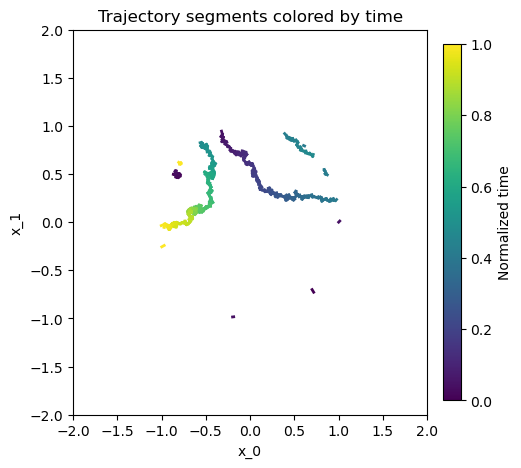

In [5]:
plot_trajectories_time_colored(traj_full, global_time=True)   # continuous across segments
# plot_trajectories_time_colored(traj_full, global_time=False)  # resets per segment

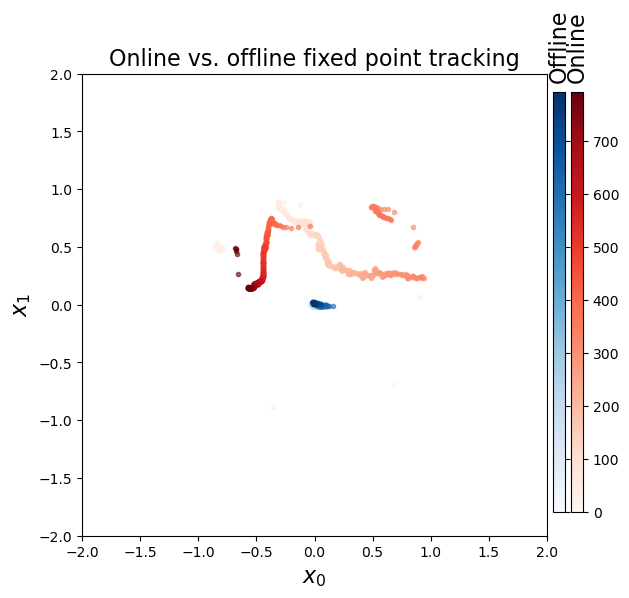

In [6]:
x_history = np.concatenate(traj_full)

fontsize = 16
fig, ax = plt.subplots(figsize=(6,6))

# Plot offline points
b_offline_all = np.concatenate([
    sliding_window_fp(traj, window_size=200)[1]
    for traj in traj_full if traj.shape[0] >= 200
])
n_off = b_offline_all.shape[0]
colors_off = cm.Blues(np.linspace(0,1,n_off))
for i in range(n_off):
    ax.plot(b_offline_all[i,0], b_offline_all[i,1], '.', color=colors_off[i], alpha=0.6)

# Plot online points
b_history = tracker.b_history
b_history_arr = np.array(b_history)
n_on = b_history_arr.shape[0]
colors_on = cm.Reds(np.linspace(0,1,n_on))
for i in range(n_on):
    ax.plot(b_history_arr[i,0], b_history_arr[i,1], '.', color=colors_on[i], alpha=0.6)

ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_xlabel("$x_0$", fontsize=fontsize)
ax.set_ylabel("$x_1$", fontsize=fontsize)
ax.set_title("Online vs. offline fixed point tracking", fontsize=fontsize)

# Create independent axes for colorbars
n_on_ff  = b_history_arr.shape[0]  # total online points

# Offline colorbar
cax_off = fig.add_axes([0.91, 0.15, 0.02, 0.7])
sm_off = plt.cm.ScalarMappable(cmap=cm.Blues, norm=plt.Normalize(vmin=0, vmax=n_on_ff))
cbar_off  = plt.colorbar(sm_off, cax=cax_off)
cbar_off.ax.set_title("Offline", pad=10, rotation=90, fontsize=fontsize)
cbar_off.ax.set_yticklabels([])  # remove ticks

# Online colorbar
cax_on = fig.add_axes([0.94, 0.15, 0.02, 0.7])
sm_on = plt.cm.ScalarMappable(cmap=cm.Reds, norm=plt.Normalize(vmin=0, vmax=n_on_ff))
cbar_on  = plt.colorbar(sm_on, cax=cax_on)
cbar_on.ax.set_title("Online", pad=10, rotation=90, fontsize=fontsize)  # label above

plt.show()

## Double well

In [7]:
# def drift_func(t, x):
#     # gradient of a quadruple (?) well
#     dx0 = x[0] - x[0]**3
#     dx1 = x[1] - x[1]**3
#     return np.array([dx0, dx1]) 

def potential(X, Y):
    return (X**2 - 1)**2 + 2 * Y**2

def drift_func(t, x):
    dx0 = -1 * x[0] * (x[0]**2 - 1)
    dx1 = -4 * x[1]
    return np.array([dx0, dx1])

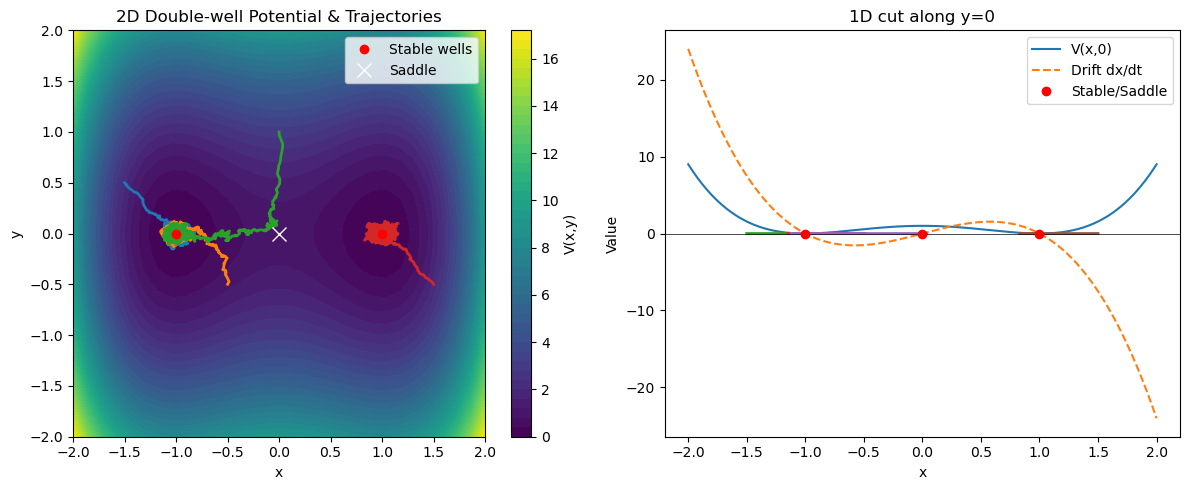

In [8]:
# Simulate multiple trajectories
x0_list = [[-1.5, 0.5], [-0.5, -0.5], [0.0, 1.0], [1.5, -0.5]]
dt = 0.01
T = 50
noise_std = 0.1  #
trajectories = [
    simulate_euler_maruyama(drift_func, np.array(x0), (0, T), dt, noise_std=noise_std)[1]
    for x0 in x0_list
]
# 2D grid for potential
x = np.linspace(-2, 2, 30)
y = np.linspace(-2, 2, 30)
X, Y = np.meshgrid(x, y)
V = potential(X, Y)

# 1D cut along y=0
x1d = np.linspace(-2, 2, 200)
V1d = potential(x1d, np.zeros_like(x1d))
drift1d = -4 * x1d * (x1d**2 - 1)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Subplot 1: 2D potential + trajectories
ax = axes[0]
cs = ax.contourf(X, Y, V, levels=50, cmap="viridis")
for traj in trajectories:
    ax.plot(traj[:,0], traj[:,1], lw=2)
ax.plot([-1, 1], [0, 0], 'ro', label="Stable wells")
ax.plot([0], [0], 'wx', markersize=10, label="Saddle")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("2D Double-well Potential & Trajectories")
ax.legend()
fig.colorbar(cs, ax=ax, label="V(x,y)")

# Subplot 2: 1D cut along y=0
ax = axes[1]
ax.plot(x1d, V1d, label="V(x,0)")
ax.plot(x1d, drift1d, label="Drift dx/dt", linestyle='--')
for traj in trajectories:
    ax.plot(traj[:,0], np.zeros_like(traj[:,0]), lw=2)
ax.axhline(0, color='k', linewidth=0.5)
ax.plot([-1, 1, 0], [0,0,0], 'ro', label="Stable/Saddle")
ax.set_xlabel("x"); ax.set_ylabel("Value")
ax.set_title("1D cut along y=0")
ax.legend()

plt.tight_layout()
plt.show()

C:\Users\abel_\AppData\Local\Temp\ipykernel_23696\3796781000.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


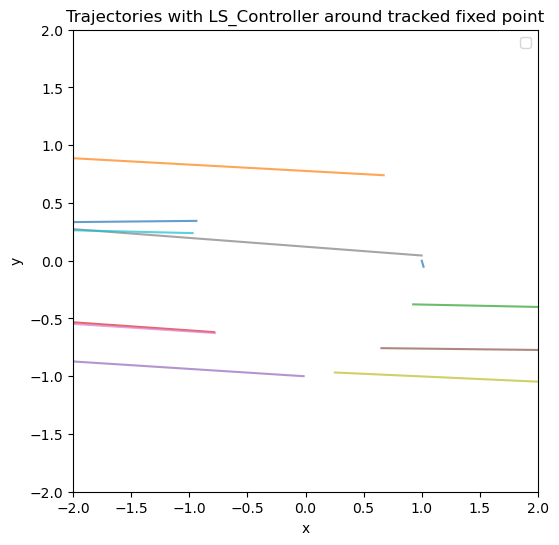

In [9]:
x0 = np.array([1., 0.])
T = 500.0
dt = 0.01

# Tracker and controller
tracker = LinearDynamicsTracker(dim=2, eta_mean=0.01, eta_M=0.01, eta_w=0.01, store_history=True)
control_vector = np.array([1.0, 0.0])
controller = LS_Controller(control_vector, tracker=tracker, apply_radius=1.0, gamma_v=0.1)

trajectories = []
#for x0 in x0_list:
t_vals, trajectories, ctrls = simulate_euler_maruyama_control_restart(drift_func, controller, x0, (0, T), dt, noise_std=0.5)
    #trajectories.append(traj)


fig, ax = plt.subplots(figsize=(6,6))
for traj in trajectories:
    ax.plot(traj[:,0], traj[:,1], alpha=0.7)

ax.set_xlim(-2,2)
ax.set_ylim(-2,2)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Trajectories with LS_Controller around tracked fixed point')
ax.legend()
plt.show()

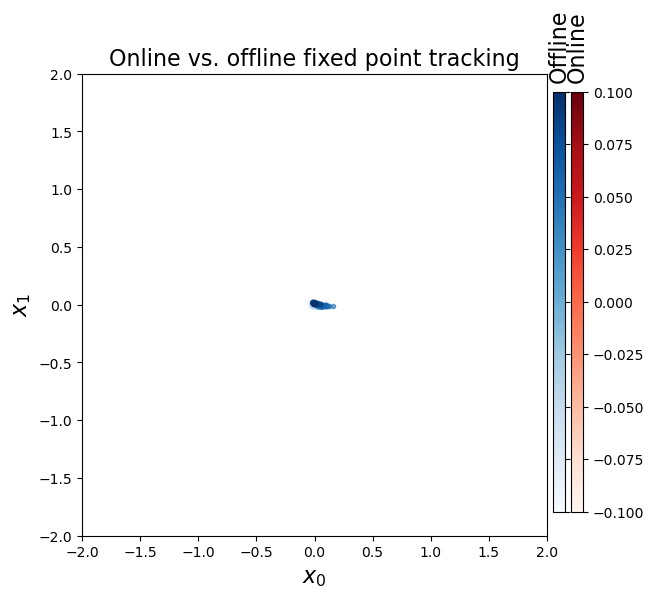

In [10]:
fontsize = 16
fig, ax = plt.subplots(figsize=(6,6))

# Plot offline points
b_offline_all = np.concatenate([
    sliding_window_fp(traj, window_size=200)[1]
    for traj in traj_full if traj.shape[0] >= 200
])
n_off = b_offline_all.shape[0]
colors_off = cm.Blues(np.linspace(0,1,n_off))
for i in range(n_off):
    ax.plot(b_offline_all[i,0], b_offline_all[i,1], '.', color=colors_off[i], alpha=0.6)

# Plot online points
b_history = tracker.b_history
b_history_arr = np.array(b_history)
n_on = b_history_arr.shape[0]
colors_on = cm.Reds(np.linspace(0,1,n_on))
for i in range(n_on):
    ax.plot(b_history_arr[i,0], b_history_arr[i,1], '.', color=colors_on[i], alpha=0.6)

ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_xlabel("$x_0$", fontsize=fontsize)
ax.set_ylabel("$x_1$", fontsize=fontsize)
ax.set_title("Online vs. offline fixed point tracking", fontsize=fontsize)

# Create independent axes for colorbars
n_on_ff  = b_history_arr.shape[0]  # total online points

# Offline colorbar
cax_off = fig.add_axes([0.91, 0.15, 0.02, 0.7])
sm_off = plt.cm.ScalarMappable(cmap=cm.Blues, norm=plt.Normalize(vmin=0, vmax=n_on_ff))
cbar_off  = plt.colorbar(sm_off, cax=cax_off)
cbar_off.ax.set_title("Offline", pad=10, rotation=90, fontsize=fontsize)
cbar_off.ax.set_yticklabels([])  # remove ticks

# Online colorbar
cax_on = fig.add_axes([0.94, 0.15, 0.02, 0.7])
sm_on = plt.cm.ScalarMappable(cmap=cm.Reds, norm=plt.Normalize(vmin=0, vmax=n_on_ff))
cbar_on  = plt.colorbar(sm_on, cax=cax_on)
cbar_on.ax.set_title("Online", pad=10, rotation=90, fontsize=fontsize)  # label above

plt.show()